# 01 Inventaire du jeu PRMI

Une ligne par image, construite par `src/prmi/inventory.py` en un seul parcours de la clé (`python src/prmi/inventory.py`). Ce notebook ne relit que le cache `data/interim/inventory.parquet`, sauf le contrôle des masques vides (200 fichiers).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd

from prmi.inventory import check_empty_masks, load_inventory
from prmi import viz

viz.apply_style()
pd.set_option('display.width', 160)

df = load_inventory()
print(df.shape)
df.head(3)

(72568, 17)


,split,folder,species,dpi,site,tube,position,date,time,row,col,has_root,mask_present,image_path,mask_path,tube_id,root_frac
0,train,Cotton_736x552_DPI150,Cotton,150,AMC,T011,55,2012-08-06,145505,<NA>,<NA>,False,True,train/images/Cotton_736x552_DPI150/Cotton_T011...,train/masks_pixel_gt/Cotton_736x552_DPI150/GT_...,Cotton_AMC_T011,0.000000
1,train,Cotton_736x552_DPI150,Cotton,150,AMC,T005,56,2012-06-22,094757,<NA>,<NA>,False,True,train/images/Cotton_736x552_DPI150/Cotton_T005...,train/masks_pixel_gt/Cotton_736x552_DPI150/GT_...,Cotton_AMC_T005,0.000000
2,train,Cotton_736x552_DPI150,Cotton,150,AMC,T004,49,2012-06-22,091912,<NA>,<NA>,True,True,train/images/Cotton_736x552_DPI150/Cotton_T004...,train/masks_pixel_gt/Cotton_736x552_DPI150/GT_...,Cotton_AMC_T004,0.013892


## Effectifs par sous-dossier et par split

Un sous-dossier correspond à une espèce et un capteur (résolution, DPI).

In [2]:
pd.crosstab(df['folder'], df['split'], margins=True, margins_name='total')[['train', 'val', 'test', 'total']]

split,train,val,test,total
folder,,,,
Cotton_736x552_DPI150,1271,564,577,2412
Papaya_736x552_DPI150,282,131,133,546
Peanut_640x480_DPI120,10087,3413,3542,17042
Peanut_736x552_DPI150,11485,3347,4793,19625
Sesame_640x480_DPI120,1438,318,404,2160
Sesame_736x552_DPI150,8637,2625,3084,14346
Sunflower_640x480_DPI120,2211,722,967,3900
Switchgrass_720x510_DPI300,2647,665,600,3912
Switchgrass_720x510_DPI300_noMask,8625,0,0,8625


In [3]:
# Part d'images avec racine (étiquette has_root du JSON)
pd.crosstab(df['folder'], df['split'], values=df['has_root'], aggfunc='mean').round(2)[['train', 'val', 'test']]

split,train,val,test
folder,,,
Cotton_736x552_DPI150,0.40,0.38,0.33
Papaya_736x552_DPI150,0.86,0.93,0.92
Peanut_640x480_DPI120,0.51,0.48,0.48
Peanut_736x552_DPI150,0.56,0.56,0.58
Sesame_640x480_DPI120,0.79,0.42,0.46
Sesame_736x552_DPI150,0.53,0.54,0.62
Sunflower_640x480_DPI120,0.44,0.29,0.49
Switchgrass_720x510_DPI300,0.91,0.94,0.70
Switchgrass_720x510_DPI300_noMask,0.22,NaN,NaN


In [4]:
# Tubes par split : les splits officiels sont-ils disjoints par tube ?
tubes = df.groupby(['folder', 'split'])['tube_id'].agg(set).unstack()
pd.DataFrame({
    'tubes train/val/test': tubes.apply(lambda r: '/'.join(str(len(r[s])) if isinstance(r[s], set) else '0' for s in ['train', 'val', 'test']), axis=1),
    'communs train-test': tubes.apply(lambda r: len(r['train'] & r['test']) if isinstance(r['test'], set) else 0, axis=1),
    'communs train-val': tubes.apply(lambda r: len(r['train'] & r['val']) if isinstance(r['val'], set) else 0, axis=1),
})

,tubes train/val/test,communs train-test,communs train-val
folder,,,
Cotton_736x552_DPI150,7/2/3,0,0
Papaya_736x552_DPI150,6/2/3,0,0
Peanut_640x480_DPI120,19/6/7,0,0
Peanut_736x552_DPI150,28/8/12,0,0
Sesame_640x480_DPI120,10/5/4,0,0
Sesame_736x552_DPI150,24/7/9,0,0
Sunflower_640x480_DPI120,9/3/4,0,0
Switchgrass_720x510_DPI300,25/6/19,1,0
Switchgrass_720x510_DPI300_noMask,57/0/0,0,0


## Masques présents et cohérence avec `has_root`

In [5]:
pd.crosstab(df['folder'], df['mask_present'])

mask_present,False,True
folder,,
Cotton_736x552_DPI150,0,2412
Papaya_736x552_DPI150,0,546
Peanut_640x480_DPI120,0,17042
Peanut_736x552_DPI150,0,19625
Sesame_640x480_DPI120,0,2160
Sesame_736x552_DPI150,0,14346
Sunflower_640x480_DPI120,0,3900
Switchgrass_720x510_DPI300,0,3912
Switchgrass_720x510_DPI300_noMask,8625,0


In [6]:
m = df[df['mask_present']]
print('has_root=1 mais masque vide :', (m['has_root'] & (m['root_frac'] == 0)).sum())
m[m['has_root'] & (m['root_frac'] == 0)][['image_path']]

has_root=1 mais masque vide : 1


,image_path
58062,val/images/Switchgrass_720x510_DPI300/Switchgr...


In [7]:
# L'inventaire suppose que les masques has_root=0 sont vides : contrôle sur 200 masques tirés au hasard.
c = check_empty_masks(df, n=200)
print('masques non vides parmi 200 has_root=0 :', (c['root_frac'] > 0).sum())

contrôle:   0%|          | 0/200 [00:00<?, ?it/s]

contrôle:  26%|██▋       | 53/200 [00:00<00:00, 521.55it/s]

contrôle:  54%|█████▎    | 107/200 [00:00<00:00, 528.14it/s]

contrôle:  81%|████████  | 162/200 [00:00<00:00, 534.48it/s]

contrôle: 100%|██████████| 200/200 [00:00<00:00, 531.21it/s]

masques non vides parmi 200 has_root=0 : 0


## Nombre de dates par tube et par position

Le dossier `noMask` (switchgrass sans masque) est exclu. Les numéros de tube BAZ de l'arachide 150 DPI reviennent en 2015 et en 2016 : rien n'indique s'il s'agit des mêmes tubes physiques, donc les dates sont comptées par saison (année).

In [8]:
d = df[df['mask_present']].assign(season=lambda x: x['date'].dt.year)
dates = d.groupby(['folder', 'tube_id', 'season', 'position'])['date'].nunique()
dates.groupby('folder').describe()[['count', 'min', '25%', '50%', '75%', 'max']]

,count,min,25%,50%,75%,max
folder,,,,,,
Cotton_736x552_DPI150,885.0,1.0,3.0,3.0,3.0,3.0
Papaya_736x552_DPI150,171.0,1.0,1.0,1.0,7.0,7.0
Peanut_640x480_DPI120,3524.0,1.0,4.0,5.0,6.0,6.0
Peanut_736x552_DPI150,5548.0,1.0,2.0,4.0,5.0,7.0
Sesame_640x480_DPI120,1423.0,1.0,1.0,1.0,2.0,4.0
Sesame_736x552_DPI150,3425.0,1.0,2.0,5.0,7.0,7.0
Sunflower_640x480_DPI120,1475.0,1.0,2.0,2.0,4.0,4.0
Switchgrass_720x510_DPI300,248.0,1.0,1.0,1.0,1.0,2.0


In [9]:
# Vue par tube : années, dates (sessions) et positions couvertes
per_tube = d.groupby(['folder', 'tube_id']).agg(
    saisons=('season', 'nunique'),
    dates=('date', 'nunique'),
    positions=('position', 'nunique'),
    images=('image_path', 'size'),
)
per_tube.groupby('folder').median()

,saisons,dates,positions,images
folder,,,,
Cotton_736x552_DPI150,1.0,3.0,70.5,189.0
Papaya_736x552_DPI150,1.0,1.0,16.0,19.0
Peanut_640x480_DPI120,1.0,6.0,111.0,544.5
Peanut_736x552_DPI150,1.5,6.5,77.0,378.5
Sesame_640x480_DPI120,1.0,1.0,73.0,83.0
Sesame_736x552_DPI150,1.0,7.0,88.5,500.0
Sunflower_640x480_DPI120,1.0,4.0,95.5,256.5
Switchgrass_720x510_DPI300,1.0,1.0,7.0,103.5


In [10]:
# Une même (tube, date, position) peut-elle avoir plusieurs images ?
key = ['folder', 'tube_id', 'date', 'position', 'row', 'col']
dup = df[df.duplicated(key, keep=False)].sort_values(key)
print(len(dup), 'images concernées')
dup.groupby('folder').size()

180 images concernées


folder
Switchgrass_720x510_DPI300_noMask    180
dtype: int64

## Part de pixels racine

Calculée sur les images `has_root=1`. Échelle logarithmique : les valeurs vont de 0,01 % à plus de 50 %.

In [11]:
r = d[d['has_root'] & (d['root_frac'] > 0)]  # exclut l'unique masque has_root=1 vide (échelle log)
r.groupby('folder')['root_frac'].describe(percentiles=[.1, .5, .9]).round(4)

,count,mean,std,min,10%,50%,90%,max
folder,,,,,,,,
Cotton_736x552_DPI150,918.0,0.0221,0.0246,0.0008,0.0034,0.0139,0.0478,0.2950
Papaya_736x552_DPI150,487.0,0.1720,0.1265,0.0020,0.0179,0.1552,0.3508,0.6495
Peanut_640x480_DPI120,8508.0,0.0427,0.0409,0.0003,0.0062,0.0306,0.0942,0.5300
Peanut_736x552_DPI150,11147.0,0.0266,0.0253,0.0001,0.0037,0.0188,0.0609,0.2015
Sesame_640x480_DPI120,1460.0,0.0337,0.0369,0.0000,0.0046,0.0240,0.0712,0.4091
Sesame_736x552_DPI150,7923.0,0.0324,0.0299,0.0001,0.0048,0.0222,0.0764,0.1914
Sunflower_640x480_DPI120,1646.0,0.0282,0.0264,0.0002,0.0050,0.0200,0.0609,0.2060
Switchgrass_720x510_DPI300,3462.0,0.0193,0.0305,0.0000,0.0011,0.0106,0.0423,0.4387


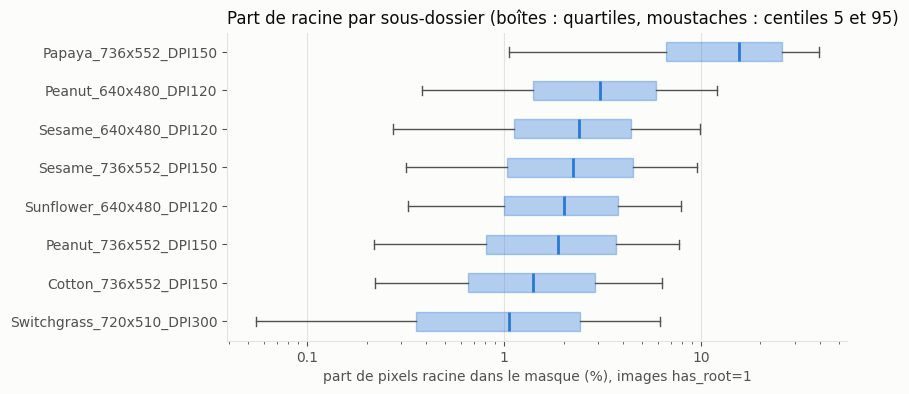

In [12]:
order = r.groupby('folder')['root_frac'].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([r.loc[r['folder'] == f, 'root_frac'] * 100 for f in order], tick_labels=order,
           orientation='horizontal', widths=0.5, whis=(5, 95), showfliers=False, patch_artist=True,
           boxprops=dict(facecolor=viz.ACCENT, edgecolor=viz.ACCENT, alpha=0.35),
           medianprops=dict(color=viz.ACCENT, linewidth=2), whiskerprops=dict(color=viz.INK_2),
           capprops=dict(color=viz.INK_2))
ax.set_xscale('log')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
ax.set_xlabel('part de pixels racine dans le masque (%), images has_root=1')
ax.set_title('Part de racine par sous-dossier (boîtes : quartiles, moustaches : centiles 5 et 95)', loc='left')
ax.grid(axis='y', visible=False)
viz.save(fig, '01_part_racine.png')

## À retenir

- 72 568 images, dont 63 943 avec masque (tout sauf `Switchgrass_..._noMask`). L'arachide domine : 19 625 images en 150 DPI, 17 042 en 120 DPI.
- Les splits officiels sont disjoints par tube (un seul tube switchgrass commun train/test) : le test officiel est déjà un jeu de « tubes jamais vus ».
- Le champ `binary_mask` du JSON vaut `N/A` pour 38 tuiles switchgrass du val alors que le masque existe : le nom du masque est dérivé du nom de l'image.
- `has_root` est fiable : 0 masque non vide sur 200 has_root=0 contrôlés, 1 seul masque vide parmi les has_root=1.
- Séries temporelles : en médiane 4 dates par tube et position et par saison pour l'arachide 150 DPI (jusqu'à 7), 5 en 120 DPI, 5 pour le sésame 150 DPI ; switchgrass, papaye et sésame 120 DPI sont presque des instantanés.
- Part de racine médiane autour de 2 % pour la plupart des espèces (arachide 150 DPI : 1,9 %), beaucoup plus élevée pour la papaye (15 %), à regarder au diagnostic.